# M3.1 · 标签工程

> 标签决定模型"学什么"。同样的特征，用不同标签训练会得到完全不同的模型。
> 本节构造收益、rank、zscore、分类、二值、风险调整等多种标签，比较其分布与适用场景。

## 一、标签类型对比

| 标签 | 目标 | 适用 |
|---|---|---|
| 未来收益 | 预测涨跌幅（回归） | 线性模型，但易受异常值影响 |
| 截面 rank | 预测相对排序（[-1,1]） | 选股，与 IC 目标一致、抗异常 |
| 截面 zscore | 标准化收益 | 回归，跨期可比 |
| 分位类别 | 预测所属分档（多分类） | 分类模型 |
| 二值 | 涨跌方向 | 二分类 |
| 风险调整 | 收益/波动 | 兼顾风险的选股 |

**关键经验**：MSE 回归目标与选股排序（IC）并不一致，A 股选股用 rank 标签往往更稳。


## 二、加载数据

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from model_lab2 import labels
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume'],
                 start_time='2018-01-01', freq='day')
cl=raw['$close'].unstack('instrument')
print('数据区间:', cl.index.min(), '->', cl.index.max())

[12152:MainThread](2026-10-31 09:39:55,422) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[12152:MainThread](2026-10-31 09:39:57,386) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[12152:MainThread](2026-10-31 09:39:57,388) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


数据区间: 2018-01-02 00:00:00 -> 2026-10-29 00:00:00


## 三、构造多种标签（5日）

In [2]:
H=5
lab_ret = labels.fwd_return_label(cl, H)
lab_rank = labels.cs_rank_label(cl, H)
lab_z = labels.cs_zscore_label(cl, H)
lab_q = labels.quantile_label(cl, H)
lab_b = labels.binary_label(cl, H)
lab_ra = labels.risk_adjusted_label(cl, H)
all_lab = {'收益':lab_ret,'rank':lab_rank,'zscore':lab_z,
           '分位类别':lab_q,'二值':lab_b,'风险调整':lab_ra}
for n, v in all_lab.items():
    print('%-6s 非空 %d' % (n, v.notna().sum().sum()))

收益     非空 566111
rank   非空 566111
zscore 非空 566111
分位类别   非空 566111
二值     非空 641700
风险调整   非空 559253


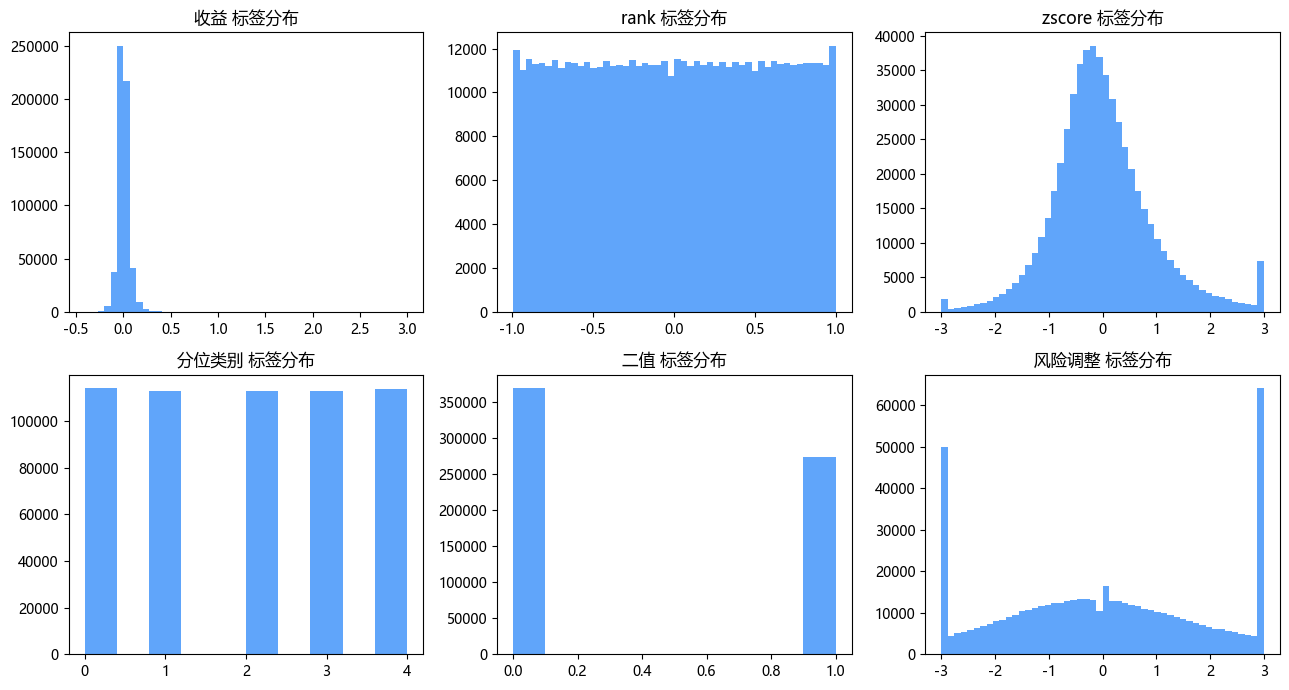

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(2, 3, figsize=(13,7))
for ax, (n, v) in zip(axes.flat, all_lab.items()):
    vals = v.stack().dropna().values
    if n in ('分位类别','二值'):
        ax.hist(vals, bins=10, color='#60a5fa')
    else:
        ax.hist(np.clip(vals,-3,3), bins=50, color='#60a5fa')
    ax.set_title(n+' 标签分布')
plt.tight_layout(); plt.show()

## 四、多周期标签

In [4]:
ml = labels.multi_horizon_labels(cl, (1,5,20))
print('多周期标签:', list(ml.keys()))
# 不同周期 rank 标签的相关性（取最后一个截面）
dt = cl.index[-6]
mc = pd.DataFrame({h: ml[h].loc[dt] for h in ml})
print('同截面多周期标签相关:')
print(mc.corr().round(3).to_string())

多周期标签: [1, 5, 20]
同截面多周期标签相关:
       1      5   20
1   1.000  0.072 NaN
5   0.072  1.000 NaN
20    NaN    NaN NaN


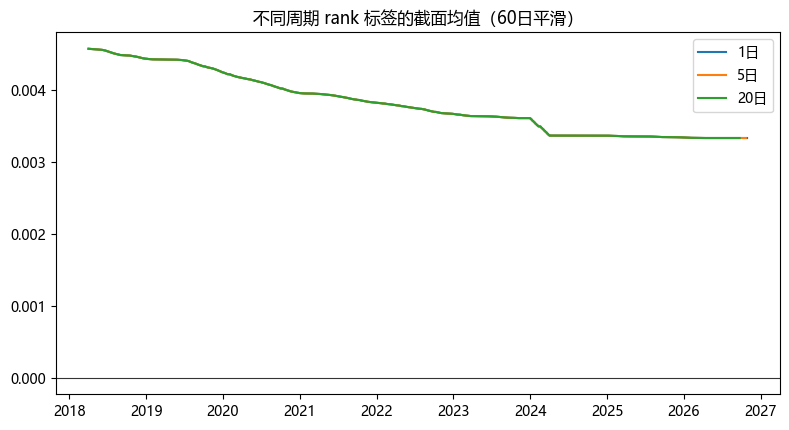

In [5]:
fig, ax = plt.subplots(figsize=(8,4.4))
for h in ml:
    s = ml[h].mean(axis=1)
    ax.plot(s.index, s.rolling(60).mean(), label='%d日'%h)
ax.axhline(0, color='#333', lw=0.8)
ax.set_title('不同周期 rank 标签的截面均值（60日平滑）'); ax.legend()
plt.tight_layout(); plt.show()

## 五、标签选择的实务建议

- 选股排序优先用 **rank 标签**，与 IC 目标一致、抗异常、跨期可比；
- 想要经济量级用 zscore/收益标签，但要去极值；
- 多周期标签可用于多任务学习，短周期信号多、长周期更稳；
- 标签的未来函数方向：用 shift(-h)，训练时严格保证只在历史特征上学习。

## 六、小结与面试要点

**面试高频：**
- 为什么用 rank 标签而不是原始收益？（答：MSE与排序目标不一致，rank抗异常、直接对齐IC）
- 标签怎么防止未来函数？（答：标签用未来数据，但特征只用历史，训练样本按时间对齐，回测再shift）
- 分类和回归标签怎么选？（答：要排序选回归/rank，只判断方向或档位选分类）
- 多周期标签有什么用？（答：多任务学习，兼顾短周期信号和长周期稳定）

## 动手练习
1. 构造全部标签并比较分布；
2. 用同一特征分别配收益和 rank 标签训练，比较样本外 IC；
3. 构造多周期标签并分析其相关性。

---
下一节 M3.2 特征选择与稳定性。